In [1]:
   import pandas as pd
   import matplotlib.pyplot as plt
   import seaborn as sns

   sns.set_theme()

In [2]:
ratings = pd.read_csv("../../data/ratings.csv")
movies = pd.read_csv("../../data/movies.csv")

ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [3]:
print("Ratings:", len(ratings))
print("Users:", ratings["userId"].nunique())
print("Movies rated:", ratings["movieId"].nunique())
print(ratings["rating"].describe())

Ratings: 100836
Users: 610
Movies rated: 9724
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


In [4]:
n_users = ratings["userId"].nunique()
n_movies = ratings["movieId"].nunique()

possible = n_users * n_movies
sparsity = 1 - len(ratings) / possible

print(f"Possible ratings: {possible:,}")
print(f"Actual ratings:   {len(ratings):,}")
print(f"Sparsity: {sparsity:.2%}")

Possible ratings: 5,931,640
Actual ratings:   100,836
Sparsity: 98.30%


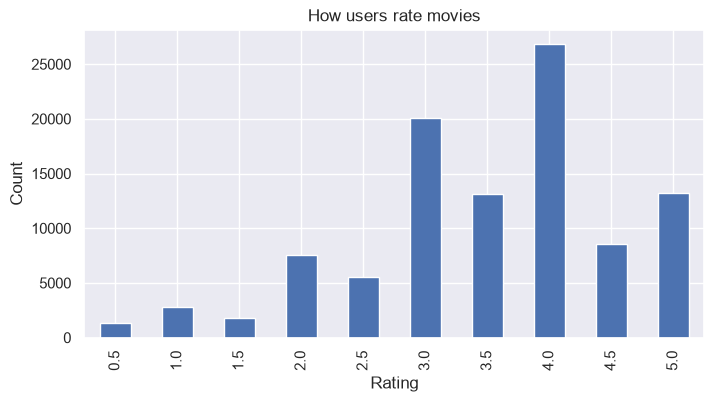

In [5]:
plt.figure(figsize=(8, 4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("How users rate movies")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64


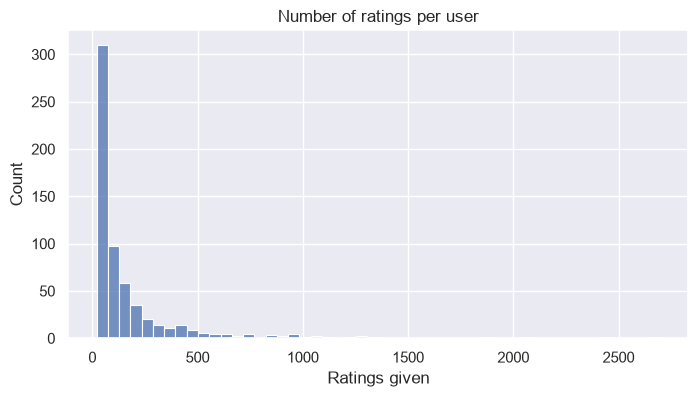

In [6]:
user_counts = ratings.groupby("userId").size()

print(user_counts.describe())

plt.figure(figsize=(8, 4))
sns.histplot(user_counts, bins=50)
plt.title("Number of ratings per user")
plt.xlabel("Ratings given")
plt.show()

count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64
Movies with only 1 rating: 3446
Movies with fewer than 5 ratings: 6074


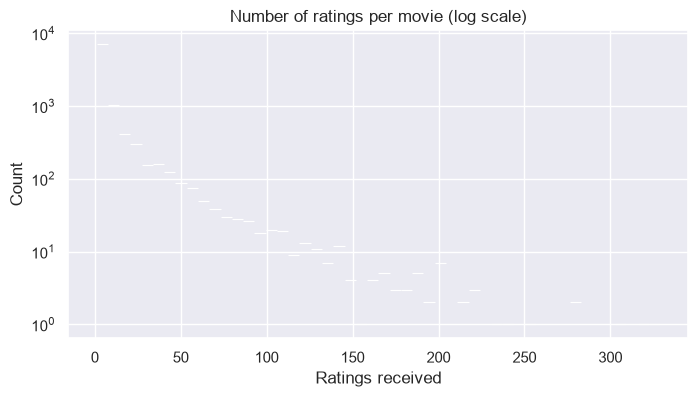

In [7]:
movie_counts = ratings.groupby("movieId").size()

print(movie_counts.describe())
print("Movies with only 1 rating:", (movie_counts == 1).sum())
print("Movies with fewer than 5 ratings:", (movie_counts < 5).sum())

plt.figure(figsize=(8, 4))
sns.histplot(movie_counts, bins=50, log_scale=(False, True))
plt.title("Number of ratings per movie (log scale)")
plt.xlabel("Ratings received")
plt.show()

In [8]:
movie_stats = ratings.groupby("movieId").agg(
    num_ratings=("rating", "count"),
    avg_rating=("rating", "mean"),
).reset_index()

movie_stats = movie_stats.merge(movies, on="movieId")

movie_stats.sort_values("avg_rating", ascending=False).head(10)[
    ["title", "avg_rating", "num_ratings"]
]

,title,avg_rating,num_ratings
7638,Paper Birds (Pájaros de papel) (2010),5.0,1
8089,"Act of Killing, The (2012)",5.0,1
9065,Jump In! (2007),5.0,1
9076,Human (2015),5.0,1
9078,L.A. Slasher (2015),5.0,1
4245,Lady Jane (1986),5.0,1
8136,Bill Hicks: Revelations (1993),5.0,1
8130,Justice League: Doom (2012),5.0,1
4240,Open Hearts (Elsker dig for evigt) (2002),5.0,1
9104,Formula of Love (1984),5.0,1


In [9]:
C = ratings["rating"].mean()                       # global average
m = movie_stats["num_ratings"].quantile(0.90)      # minimum votes needed

print(f"Global mean C = {C:.2f}, min votes m = {m:.0f}")

qualified = movie_stats[movie_stats["num_ratings"] >= m].copy()

def weighted_rating(row):
    v = row["num_ratings"]
    R = row["avg_rating"]
    return (v / (v + m)) * R + (m / (v + m)) * C

qualified["score"] = qualified.apply(weighted_rating, axis=1)

top = qualified.sort_values("score", ascending=False).head(10)
top[["title", "avg_rating", "num_ratings", "score"]]

Global mean C = 3.50, min votes m = 27


,title,avg_rating,num_ratings,score
277,"Shawshank Redemption, The (1994)",4.429022,317,4.356227
659,"Godfather, The (1972)",4.289062,192,4.191973
2224,Fight Club (1999),4.272936,218,4.187927
224,Star Wars: Episode IV - A New Hope (1977),4.231076,251,4.160223
46,"Usual Suspects, The (1995)",4.237745,204,4.151697
461,Schindler's List (1993),4.225000,220,4.145919
257,Pulp Fiction (1994),4.197068,307,4.140844
897,Star Wars: Episode V - The Empire Strikes Back...,4.215640,211,4.134630
1938,"Matrix, The (1999)",4.192446,278,4.131285
921,"Godfather: Part II, The (1974)",4.259690,129,4.128475


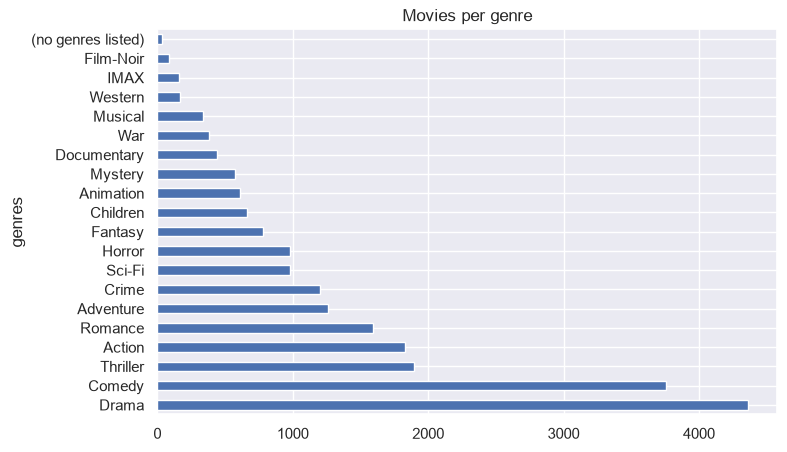

In [10]:
genre_counts = movies["genres"].str.split("|").explode().value_counts()

plt.figure(figsize=(8, 5))
genre_counts.plot(kind="barh")
plt.title("Movies per genre")
plt.show()

In [11]:
def popular_movies(n=10):
    return top.head(n)[["title", "avg_rating", "num_ratings", "score"]]

popular_movies(5)

,title,avg_rating,num_ratings,score
277,"Shawshank Redemption, The (1994)",4.429022,317,4.356227
659,"Godfather, The (1972)",4.289062,192,4.191973
2224,Fight Club (1999),4.272936,218,4.187927
224,Star Wars: Episode IV - A New Hope (1977),4.231076,251,4.160223
46,"Usual Suspects, The (1995)",4.237745,204,4.151697
